4. Clustering

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR = Path("../reports/figures")
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")


def save_figure(fig, name):
    """Save a figure in reports/figures for the presentation."""
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

KMeans is the algorithm, silhouette_score is a metric to evaluate the quality of the clustering, and StandardScaler is used to standardize the features before clustering.

RANDOM_STATE = 42 set the K-means randomic start point; 42 is a convention.

In [2]:
df_mun = pd.read_csv(PROCESSED_DIR / "municipalities_indicators.csv",
                     dtype={"REF_AREA": str, "COD_REG": str},
                     na_values=[""])

AREA_NAMES = {1: "North-West", 2: "North-East", 3: "Centre", 4: "South", 5: "Islands"}
area_order = list(AREA_NAMES.values())
df_mun["macro_area"] = df_mun["COD_RIP"].astype(int).map(AREA_NAMES)
df_mun["is_provincial_capital"] = df_mun["CC_UTS"].astype(int) == 1

df_cluster = df_mun[df_mun["above_threshold"]].copy()
print("Municipalities used for clustering:", len(df_cluster))

Municipalities used for clustering: 2180


We decided to use only the municipalities above the threshold for clustering, because the others are too small and have too few accidents to be relevant.

In [3]:
FEATURES = ["accidents_per_1000_inh", "accidents_per_km2", "deaths_per_100_accidents"]

X_log = np.log1p(df_cluster[FEATURES])
print("Skewness after log transform:")
print(X_log.skew().round(2))

X = StandardScaler().fit_transform(X_log)

Skewness after log transform:
accidents_per_1000_inh      0.56
accidents_per_km2           1.35
deaths_per_100_accidents    0.21
dtype: float64


We applied two transformation to the featueres, due to EDA results: log transform to reduce skewness, and standardization to make the features comparable.

We use log(1+x) instead of log(x) to avoid problems with zero values.

StandardScaler rescales each variable to a mean of 0 and a standard deviation of 1. The three variables must have the same weight in the clustering, otherwise the variable with the largest range will dominate the others.

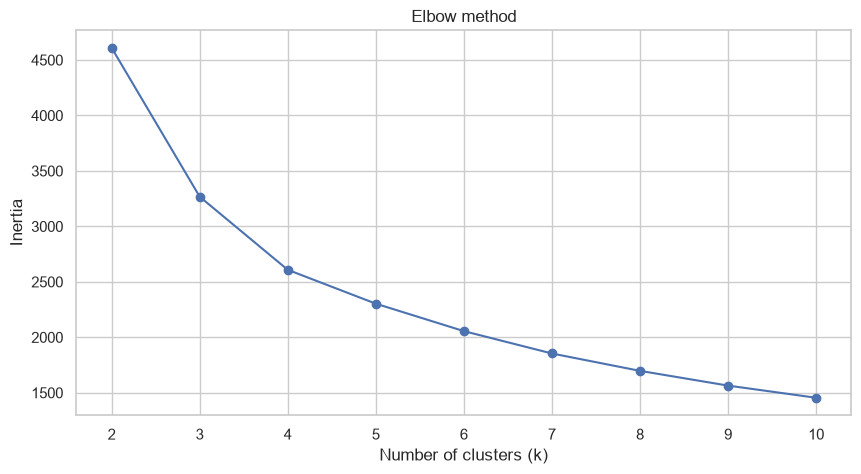

,k,inertia
0,2,4610.263
1,3,3267.576
2,4,2608.271
3,5,2303.018
4,6,2055.528
5,7,1853.904
6,8,1697.237
7,9,1564.332
8,10,1454.684


In [5]:
k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertias.append(model.inertia_)
    

fig, (ax1) = plt.subplots(1, figsize=(10, 5))

ax1.plot(k_values, inertias, marker="o")
ax1.set_title("Elbow method")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Inertia")

save_figure(fig, "05_choosing_k")
plt.show()

pd.DataFrame({"k": k_values, "inertia": inertias}).round(3)

To decide how many cluster to use, we can use the elbow method, which consists in plotting the inertia (sum of squared distances to the closest cluster center) as a function of the number of clusters.

The optimal number of clusters is the one where the inertia starts to decrease more slowly (the "elbow" of the curve).

In this case, it seems that 4 clusters could be a good choice (beacause the inertia decreases significantly from 3 to 4 clusters, but not so much from 4 to 5 clusters).

So, we're gonna use k=4

In [ ]:
K = 4

kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
df_cluster["cluster"] = kmeans.fit_predict(X)

df_cluster["cluster"].value_counts().sort_index()

cluster
0    793
1    294
2    623
3    470
Name: count, dtype: int64

In [7]:
profile = df_cluster.groupby("cluster").agg(
    municipalities=("REF_AREA", "count"),
    median_population=("POP_RES", "median"),
    share_capitals=("is_provincial_capital", "mean"),
    accidents_per_1000_inh=("accidents_per_1000_inh", "median"),
    accidents_per_km2=("accidents_per_km2", "median"),
    deaths_per_100_accidents=("deaths_per_100_accidents", "median"),
)
display(profile.round(2))

pd.crosstab(df_cluster["cluster"], df_cluster["macro_area"], normalize="index")[area_order].round(2)

,municipalities,median_population,share_capitals,accidents_per_1000_inh,accidents_per_km2,deaths_per_100_accidents
cluster,,,,,,
0,793,10364.0,0.01,1.99,0.51,4.13
1,294,23955.0,0.18,3.29,5.33,0.81
2,623,8788.0,0.02,2.11,0.73,0.00
3,470,11746.0,0.08,3.76,1.04,2.21


macro_area,North-West,North-East,Centre,South,Islands
cluster,,,,,
0,0.19,0.30,0.15,0.24,0.13
1,0.49,0.14,0.11,0.18,0.07
2,0.30,0.27,0.14,0.22,0.07
3,0.23,0.33,0.29,0.10,0.05


We use the profile function to summarize the characteristics of each cluster, and the crosstab function to see how the clusters are distributed across the macro areas.

In [ ]:
# Let's give a name to each cluster and a color for the plots

CLUSTER_NAMES = {
    0: "Low frequency, high severity",
    1: "Dense urban areas",
    2: "Low risk, low severity",
    3: "High accident rate",
}
CLUSTER_COLORS = {
    "Dense urban areas": "#d62728",
    "High accident rate": "#ff7f0e",
    "Low frequency, high severity": "#9467bd",
    "Low risk, low severity": "#2ca02c",
}
cluster_order = list(CLUSTER_COLORS.keys())

df_cluster["cluster_name"] = df_cluster["cluster"].map(CLUSTER_NAMES)
df_cluster["cluster_name"].value_counts()

cluster_name
Low frequency, high severity    793
Low risk, low severity          623
High accident rate              470
Dense urban areas               294
Name: count, dtype: int64

Let's see the 8 most populated municipalities in each cluster.

In [ ]:
for c in sorted(df_cluster["cluster_name"].unique()):
    largest = df_cluster[df_cluster["cluster_name"] == c].nlargest(8, "POP_RES")
    print(f"{c}: {', '.join(largest['COMUNE'])}")

Dense urban areas: Roma, Milano, Napoli, Torino, Palermo, Genova, Bologna, Firenze
High accident rate: Venezia, Taranto, Perugia, Ravenna, Foggia, Ferrara, Latina, Sassari
Low frequency, high severity: Giugliano in Campania, Andria, Guidonia Montecelio, Marsala, Corigliano-Rossano, Altamura, Quartu Sant'Elena, Lamezia Terme
Low risk, low severity: Reggio di Calabria, Catanzaro, Ragusa, Caserta, L'Aquila, Pomezia, Anzio, Molfetta


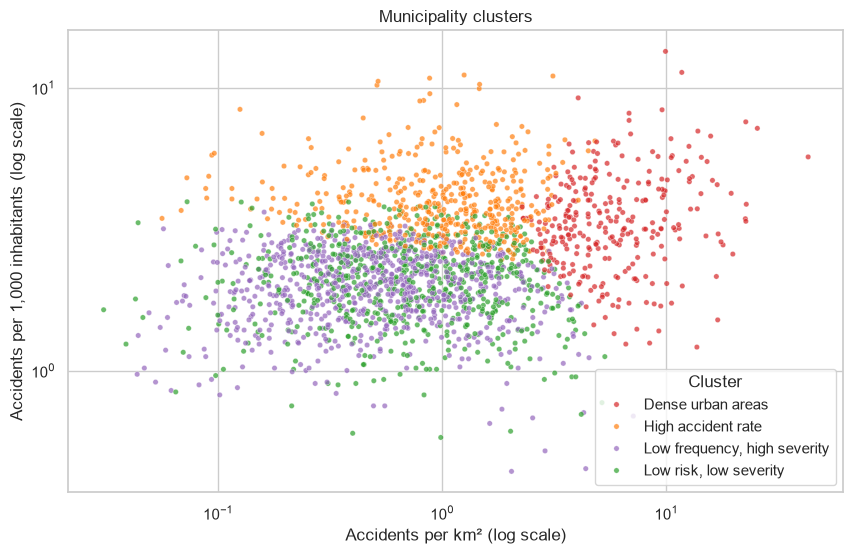

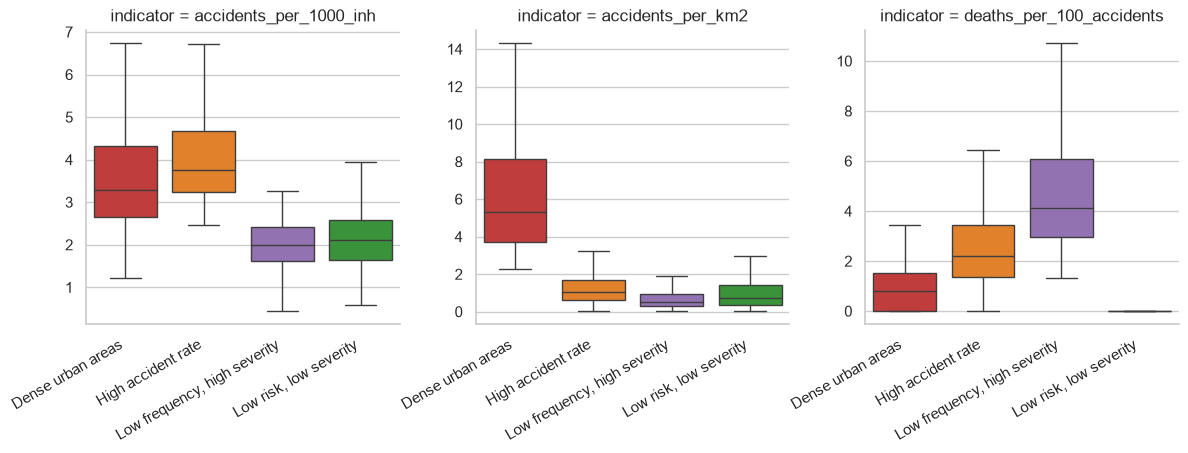

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_cluster, x="accidents_per_km2", y="accidents_per_1000_inh",
                hue="cluster_name", hue_order=cluster_order, palette=CLUSTER_COLORS,
                s=15, alpha=0.7, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Accidents per km² (log scale)")
ax.set_ylabel("Accidents per 1,000 inhabitants (log scale)")
ax.set_title("Municipality clusters")
ax.legend(title="Cluster")
save_figure(fig, "06_clusters_scatter")
plt.show()

long = df_cluster.melt(id_vars="cluster_name", value_vars=FEATURES,
                       var_name="indicator", value_name="value")
g = sns.catplot(data=long, x="cluster_name", y="value", col="indicator",
                kind="box", order=cluster_order, palette=CLUSTER_COLORS,
                hue="cluster_name", legend=False,
                sharey=False, showfliers=False, height=4)
g.set_xticklabels(rotation=30, horizontalalignment="right")
g.set_axis_labels("", "")
save_figure(g.fig, "07_clusters_boxplots")
plt.show()

The first plot shows the clusters in a scatter plot, with the two main indicators on the axes.

We have to remember that clustering uses three indicators, plot shows only two, so the clusters are not perfectly separated in this plot, but we can see that they are quite distinct.

The second plot shows boxplots of the three indicators for each cluster, to see how they differ.

In [18]:
print("Share of municipalities with zero deaths, by cluster:")
print(df_cluster.groupby("cluster_name")["deaths"].apply(lambda s: (s == 0).mean()).round(2))


Share of municipalities with zero deaths, by cluster:
cluster_name
Dense urban areas               0.28
High accident rate              0.11
Low frequency, high severity    0.00
Low risk, low severity          0.91
Name: deaths, dtype: float64


We did this check beacause cluster 2 has nearly 0 deaths per 100 accidents.

As we can see, cluster 2 is composed by 91% of municipalities with zero deaths (probably small municipalities) and 9% of municipalities with low gravity accidents.

We see, also, that cluster 0 has 0 municipalities with 0 deaths; this show that the separation between cluster basically depends if there is an accident between 2022-2023 or not.

In [17]:
df_mun = df_mun.drop(columns=["cluster", "cluster_name"], errors="ignore").merge(
    df_cluster[["REF_AREA", "cluster", "cluster_name"]], on="REF_AREA", how="left"
)
df_mun["cluster"] = df_mun["cluster"].astype("Int64")
df_mun["cluster_name"] = df_mun["cluster_name"].fillna("Below threshold")

df_mun.to_csv(PROCESSED_DIR / "municipalities_clusters.csv", index=False)
df_mun["cluster_name"].value_counts()

cluster_name
Below threshold                 5720
Low frequency, high severity     793
Low risk, low severity           623
High accident rate               470
Dense urban areas                294
Name: count, dtype: int64